# Синтетические данные с известной топологией — отчёт

**Задача 5 первого этапа.** Библиотека `tdadyn.synthetic`: генераторы наборов данных,
у которых правильный ответ известен **заранее**, а не получен из прогона алгоритма.

Отчёт проходит по сессиям S1–S9: что построено, какие решения приняты на развилках,
что измерено и чего эти данные не делают.

---

## Принцип, из которого следует всё остальное

> Ожидаемые числа Бетти — это **вход**, а не выход. Если тест не сходится, ошибка
> в генераторе, в сэмплировании или в параметрах проверки, но **не** в таблице ожиданий.

Отсюда три следствия, которые видны в каждом разделе ниже:

1. **Двойная проверка.** Путь A — основной пайплайн (`ripser`), путь B — независимая
   реализация над $\mathbb{Z}/2$ через ранги граничных матриц. Тест требует согласия
   A, B и таблицы из документа.
2. **Числа в документах — измерения.** Если в `method.md` стоит значение, оно снято
   прогоном, и рядом сказано, на чём именно.
3. **Порядок работ.** Данные делаются раньше алгоритмов (Задача 2): иначе
   валидировать нечем, и появляется соблазн объявить истиной то, что выдал алгоритм.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})

from tdadyn.synthetic import (
    STATIC_GENERATORS, adjacency_from_snapshot, build_dynamic_graph, build_dynamic_sbm,
    build_network, build_null_cloud, build_null_graph, build_series, build_static_cloud,
    edge_count, load_config, make_jittered_cloud, noise_stream, pairwise_distances,
    persistence_diagrams, reference, rng_for, significant_betti,
)
from tdadyn.synthetic import sliding_window as sw

CONFIG = load_config("../config.yaml")
TOPOLOGY = CONFIG.topology_check
print(f"конфиг загружен, seed {CONFIG.seed}, поле Z/{TOPOLOGY.coeff_field}, "
      f"max_homology_dim {TOPOLOGY.max_homology_dim}")

конфиг загружен, seed 20260201, поле Z/2, max_homology_dim 2


## Что построено: 38 наборов

`family` — раскладка на диске, `truth_kind` — **род истины**. До семейства 3 они
совпадали; динамическая SBM — первый объект, где расходятся: на диске это динамический
граф, а истина у неё разбиение, и баркода среди неё нет вовсе.

In [2]:
from tdadyn.synthetic.build import FAMILY_CHOICES, build_all, replace_output_root
import tempfile, pathlib, time

with tempfile.TemporaryDirectory() as tmp:
    started = time.perf_counter()
    ENTRIES = build_all(replace_output_root(CONFIG, pathlib.Path(tmp)), FAMILY_CHOICES)
    elapsed = time.perf_counter() - started

rows = {}
for e in ENTRIES:
    rows.setdefault((e.family, e.generator), 0)
    rows[(e.family, e.generator)] += 1

print(f"{'family':<15}{'generator':<20}{'наборов':>8}")
print("-" * 43)
for (family, generator), n in sorted(rows.items()):
    print(f"{family:<15}{generator:<20}{n:>8}")
print("-" * 43)
print(f"{'ИТОГО':<35}{len(ENTRIES):>8}")
print(f"\nполная сборка: {elapsed:.1f} с")

family         generator            наборов
-------------------------------------------
dynamic_graph  cycle_lifecycle            1
dynamic_graph  dynamic_sbm                1
dynamic_graph  geometric_loop             1
noisy          missing_edges              8
noisy          point_jitter               4
noisy          spurious_edges             8
noisy          weight_jitter              4
null           erdos_renyi                1
null           uniform_cloud              1
series         kuramoto                   1
series         roessler                   1
static_cloud   circle                     1
static_cloud   figure_eight               1
static_cloud   hopf_link                  1
static_cloud   klein_bottle               1
static_cloud   sphere                     1
static_cloud   torus                      1
static_cloud   two_circles                1
-------------------------------------------
ИТОГО                                    38

полная сборка: 1.4 с


---
# S1–S2. Каркас и эталонная реализация

Эталон (путь B) сделан **раньше генераторов**: без него нечем проверять. Он намеренно
медленный и работает только над $\mathbb{Z}/2$ — его единственное назначение
в прозрачности, а не в скорости.

Два слоя снимают развилку про размерность обрыва: движок гомологий принимает явный
список симплексов, построитель флаг-комплекса перечисляет **все** клики каждого размера
и строит до размерности $k_{\max}+1$.

In [3]:
def flag_faces(adjacency):
    complex_ = reference.flag_complex(adjacency, threshold=0.5, max_homology_dim=2, max_nodes=30)
    betti = reference.betti_numbers_of_graph(adjacency, threshold=0.5, max_homology_dim=2,
                                             max_nodes=30)
    return complex_.face_counts(), tuple(betti[k] for k in range(3))

def complete(n):
    a = np.ones((n, n)); np.fill_diagonal(a, 0.0); return a

def multipartite(sizes):
    labels = np.repeat(np.arange(len(sizes)), sizes)
    a = (labels[:, None] != labels[None, :]).astype(float)
    return a

cases = [("K3 (треугольник)", complete(3), "заполнен: beta_1 = 0, а цикломатическое 1"),
         ("K4", complete(4), "сплошной тетраэдр; обрыв на dim 2 дал бы beta_2 = 1"),
         ("K_{2,2,2} (октаэдр)", multipartite([2, 2, 2]), "настоящая полость без 3-симплексов")]

print(f"{'граф':<22}{'грани по размерностям':<26}{'beta':<12}что ловит")
print("-" * 96)
for name, adjacency, why in cases:
    faces, betti = flag_faces(adjacency)
    print(f"{name:<22}{str(faces):<26}{str(betti):<12}{why}")

граф                  грани по размерностям     beta        что ловит
------------------------------------------------------------------------------------------------
K3 (треугольник)      (3, 3, 1)                 (1, 0, 0)   заполнен: beta_1 = 0, а цикломатическое 1
K4                    (4, 6, 4, 1)              (1, 0, 0)   сплошной тетраэдр; обрыв на dim 2 дал бы beta_2 = 1
K_{2,2,2} (октаэдр)   (6, 12, 8)                (1, 0, 1)   настоящая полость без 3-симплексов


Счёт граней $K_4$ равен (4, 6, 4, 1) — это и есть проверка на то, что перечисляются
**все** клики, а не только максимальные: `networkx.find_cliques` вернул бы один тетраэдр
без рёбер и треугольников, граничные матрицы не сошлись бы по размерностям,
а $\beta_1$ вырос бы с 0 до 3.

---
# S3–S4. Статические облака: семейство 1

Семь объектов с аналитически известной топологией. Числа Бетти взяты из таблицы
`method.md` §1.2 — они вход, а не результат.

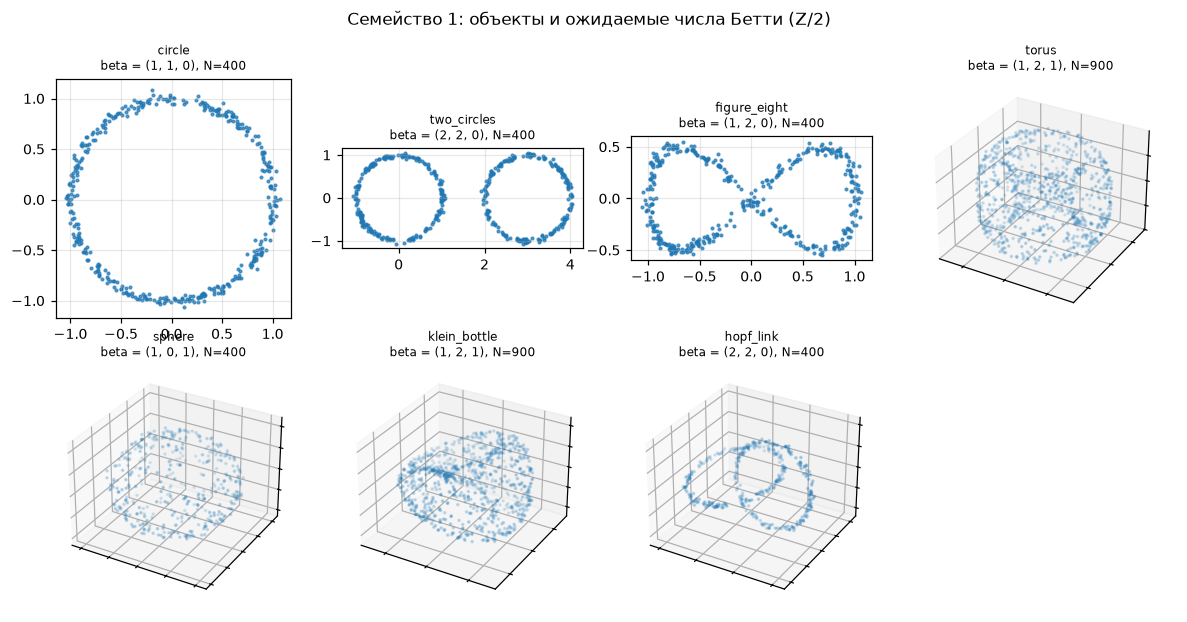

In [4]:
clouds = {name: build_static_cloud(name, CONFIG) for name in STATIC_GENERATORS}

fig = plt.figure(figsize=(13, 6.2))
for i, (name, dataset) in enumerate(clouds.items(), 1):
    pts = dataset.points
    if pts.shape[1] == 2:
        ax = fig.add_subplot(2, 4, i)
        ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.7)
        ax.set_aspect("equal")
    else:
        ax = fig.add_subplot(2, 4, i, projection="3d")
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=2, alpha=0.5)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    betti = dataset.ground_truth.expected_betti
    ax.set_title(f"{name}\nbeta = {tuple(betti[k] for k in range(3))}, N={len(pts)}",
                 fontsize=8)
fig.suptitle("Семейство 1: объекты и ожидаемые числа Бетти (Z/2)", fontsize=11)
fig.tight_layout(); plt.show()

Бутылка Клейна вложена в $\mathbb{R}^4$ и показана проекцией на первые три
координаты: в $\mathbb{R}^3$ существует лишь погружение с самопересечением, которое
испортило бы ground-truth.

Тор и бутылка Клейна строятся **rejection sampling** по элементу площади. Наивная
выборка равномерных параметров пересэмплирует внутренний обод и способна съесть бар
$\beta_2$ — это тот случай, где неверная реализация выглядит правдоподобно.

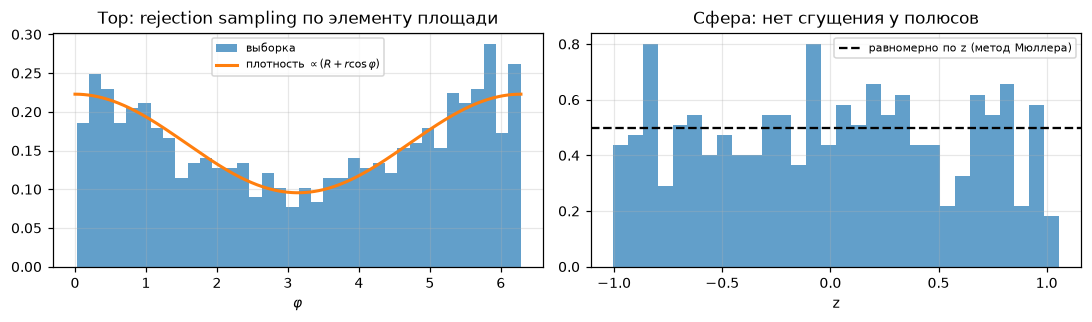

In [5]:
phi = np.linspace(0, 2 * np.pi, 400)
R, r = CONFIG.static_clouds.torus.R, CONFIG.static_clouds.torus.r
density = (R + r * np.cos(phi)) / (2 * np.pi * R)

torus = clouds["torus"].points
angle = np.arctan2(torus[:, 2], np.hypot(torus[:, 0], torus[:, 1]) - R) % (2 * np.pi)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(angle, bins=36, density=True, alpha=0.7, label="выборка")
ax[0].plot(phi, density, lw=2, label=r"плотность $\propto (R + r\cos\varphi)$")
ax[0].set_title("Тор: rejection sampling по элементу площади"); ax[0].legend(fontsize=7)
ax[0].set_xlabel(r"$\varphi$")

sphere = clouds["sphere"].points
ax[1].hist(sphere[:, 2], bins=30, density=True, alpha=0.7)
ax[1].axhline(0.5, color="k", lw=1.5, ls="--", label="равномерно по z (метод Мюллера)")
ax[1].set_title("Сфера: нет сгущения у полюсов"); ax[1].legend(fontsize=7)
ax[1].set_xlabel("z")
fig.tight_layout(); plt.show()

## Главный результат S4: критерий значимости пришлось заменить

Правило «бар значим, если персистентность $\ge$ доля диаметра» **непригодно**, и это
установлено измерением, а не соображениями. Оно ошибается **в обе стороны**:

- на анизотропных объектах (тор, Клейн) теряет $H_2$: бар живёт на масштабе малого
  радиуса, а порог нормирован на диаметр;
- на компактных (сфера) даёт лишние петли в $H_1$.

Диапазоны сигнала и шума в долях диаметра **перекрываются**, поэтому настройкой
константы это не лечится.

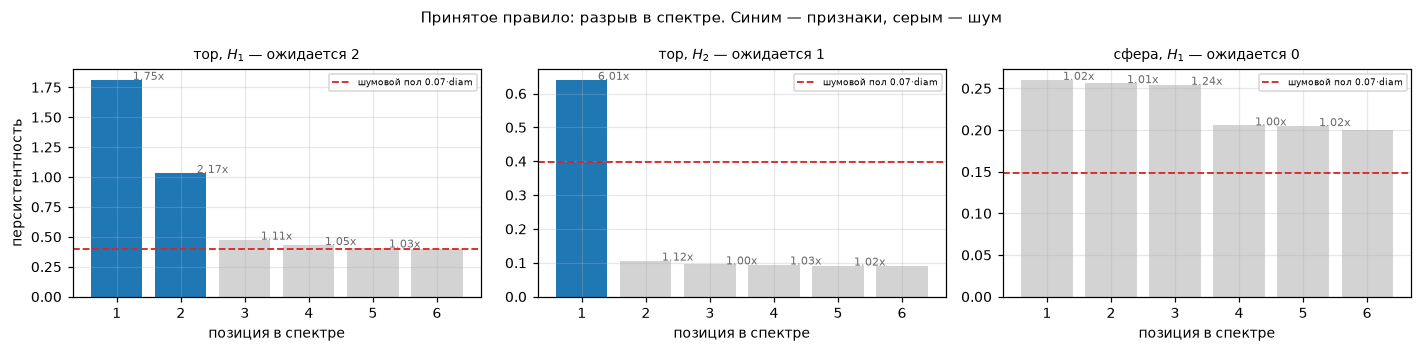

In [6]:
def spectrum(points, dim, n=6):
    d = pairwise_distances(points)
    dgm = persistence_diagrams(d, max_homology_dim=2, coeff_field=TOPOLOGY.coeff_field)[dim]
    finite = dgm[np.isfinite(dgm[:, 1])]
    pers = np.sort(finite[:, 1] - finite[:, 0])[::-1]
    return pers[:n], d.max()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
panels = [("torus", 1, 2, "тор, $H_1$ — ожидается 2"),
          ("torus", 2, 1, "тор, $H_2$ — ожидается 1"),
          ("sphere", 1, 0, "сфера, $H_1$ — ожидается 0")]
for ax, (name, dim, expected, title) in zip(axes, panels):
    pers, diam = spectrum(clouds[name].points, dim)
    floor = TOPOLOGY.gap_noise_floor_ratio * diam
    ax.bar(range(1, len(pers) + 1), pers, color=["tab:blue"] * expected +
           ["lightgray"] * (len(pers) - expected))
    ax.axhline(floor, color="tab:red", ls="--", lw=1.2,
               label=f"шумовой пол {TOPOLOGY.gap_noise_floor_ratio}·diam")
    for i in range(len(pers) - 1):
        if pers[i + 1] > 0:
            ax.text(i + 1.5, pers[i], f"{pers[i] / pers[i + 1]:.2f}x", fontsize=7,
                    ha="center", color="dimgray")
    ax.set_title(title, fontsize=9); ax.set_xlabel("позиция в спектре"); ax.legend(fontsize=6)
axes[0].set_ylabel("персистентность")
fig.suptitle("Принятое правило: разрыв в спектре. Синим — признаки, серым — шум", fontsize=10)
fig.tight_layout(); plt.show()

**Принятое правило — разрыв в спектре с шагом в пыль.** Внутри каждой размерности:
персистентности сортируются, бары ниже шумового пола откладываются, ищется наибольшее
отношение соседних значений **включая шаг от последнего выжившего к первому
отложенному**, и $\beta_k$ равно позиции этого разрыва.

Шаг в пыль введён ради случая $\beta_k = 0$: без него правило всегда возвращает
не меньше одного признака. Он же чинит две непересекающиеся окружности, где над полом
остаются два почти равных бара (0.83 и 0.79) и разрыва между ними нет.

**Результат калибровки:** правило верно на всех 54 комбинациях (9 случаев × 3 сида ×
2 уровня шума). Параметры взяты из **центра** области нулевых промахов, а не с края:
нуль держится при поле 0.05–0.10 и разрыве 1.45–1.62; принято 0.07 и 1.55.
Старое правило на той же таблице даёт 9 промахов.

In [7]:
print("Проверка: критерий против таблицы ожиданий (путь A, чистые облака)\n")
print(f"{'объект':<16}{'ожидание':<12}{'измерено':<12}")
print("-" * 40)
for name, dataset in clouds.items():
    expected = dataset.ground_truth.expected_betti
    measured = significant_betti(
        pairwise_distances(dataset.points), max_homology_dim=2,
        coeff_field=TOPOLOGY.coeff_field, criterion=TOPOLOGY.criterion,
        gap_noise_floor_ratio=TOPOLOGY.gap_noise_floor_ratio,
        gap_min_ratio=TOPOLOGY.gap_min_ratio)
    exp, got = tuple(expected[k] for k in range(3)), tuple(measured[k] for k in range(3))
    print(f"{name:<16}{str(exp):<12}{str(got):<12}{'' if exp == got else '  <-- РАСХОЖДЕНИЕ'}")

Проверка: критерий против таблицы ожиданий (путь A, чистые облака)

объект          ожидание    измерено    
----------------------------------------


circle          (1, 1, 0)   (1, 1, 0)   


two_circles     (2, 2, 0)   (2, 2, 0)   


figure_eight    (1, 2, 0)   (1, 2, 0)   


torus           (1, 2, 1)   (1, 2, 1)   


sphere          (1, 0, 1)   (1, 0, 1)   


klein_bottle    (1, 2, 1)   (1, 2, 1)   


hopf_link       (2, 2, 0)   (2, 2, 0)   


**Зацепление Хопфа даёт $\beta_0 = 2$, и это не ошибка.** Две сцепленные окружности
имеют ровно те же гомологии, что и две разъединённые: зацепление — свойство вложения,
а не гомотопического типа. Набор служит геометрическим стресс-тестом (пайплайн не должен
преждевременно склеивать близко проходящие компоненты), а не источником отдельной
топологической подписи.

---
# S5. Облако → взвешенная сеть

Мост к Задаче 3: тот же тип объекта, что функциональный коннектом. Два пути — гауссово
ядро и геодезика по $k$-NN.

**$k$ работает в окне, а не «чем больше, тем лучше».** Снизу граф распадается,
сверху наступает короткое замыкание: появляются хорды-срезки, и внутренняя метрика
вырождается в объемлющую. Дешёвый сторож — отношение
$\mathrm{diam}_{geo}/\mathrm{diam}_{euclid}$: приближение к единице означает вырождение.

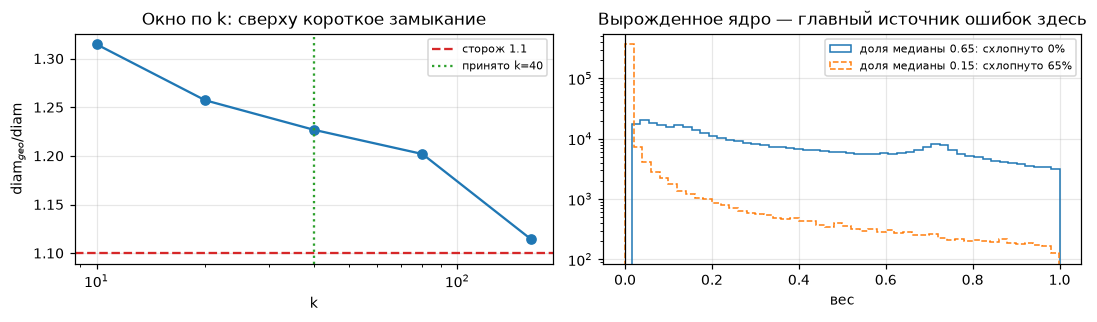

In [8]:
from tdadyn.synthetic.network import (collapsed_weight_fraction, gaussian_kernel,
                                      geodesic_diameter_ratio, kernel_width,
                                      knn_geodesic_distances)

net = CONFIG.network_from_cloud
torus_d = pairwise_distances(clouds["torus"].points)
ks = [10, 20, 40, 80, 160]
ratios = []
for k in ks:
    geo = knn_geodesic_distances(torus_d, k=k, symmetrize=net.knn_symmetrize)
    ratios.append(geodesic_diameter_ratio(geo, torus_d))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ks, ratios, "o-")
ax[0].axhline(net.min_geodesic_diameter_ratio, color="tab:red", ls="--",
              label=f"сторож {net.min_geodesic_diameter_ratio}")
ax[0].axvline(net.knn_k, color="tab:green", ls=":", label=f"принято k={net.knn_k}")
ax[0].set_xscale("log"); ax[0].set_xlabel("k"); ax[0].set_ylabel(r"diam$_{geo}$/diam")
ax[0].set_title("Окно по k: сверху короткое замыкание"); ax[0].legend(fontsize=7)

for fraction, style in ((net.kernel_sigma_median_fraction, "-"), (0.15, "--")):
    sigma = kernel_width(torus_d, median_fraction=fraction)
    w = gaussian_kernel(torus_d, sigma=sigma)
    collapsed = collapsed_weight_fraction(w)
    ax[1].hist(w[np.triu_indices_from(w, 1)], bins=50, histtype="step", ls=style,
               label=f"доля медианы {fraction}: схлопнуто {collapsed:.0%}")
ax[1].axvline(1e-6, color="k", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("вес"); ax[1].legend(fontsize=7)
ax[1].set_title("Вырожденное ядро — главный источник ошибок здесь")
fig.tight_layout(); plt.show()

Ширина ядра задаётся **в долях медианного попарного расстояния**, а не абсолютным
числом: объекты семейства 1 различаются масштабом, и абсолютное значение, подходящее
одному, схлопывает другой. Измерено: при $\sigma = 0.5$ и диаметре тора 5.71 доля весов
ниже $10^{-6}$ составляет 60%, и преобразование $1-w$ работает с уже уничтоженными
данными.

---
# S6. Динамические графы с запланированными событиями

Первый набор для Задачи 2: последовательность снимков, где в заранее заданные моменты
происходят рождение и гибель топологических признаков.

Истина двойная и **из двух независимых источников**: `events` — намерение планировщика,
`betti_curve` — посчитана эталонной реализацией по **записанным снимкам**, а не по
внутреннему состоянию планировщика. Тест требует их точного совпадения.

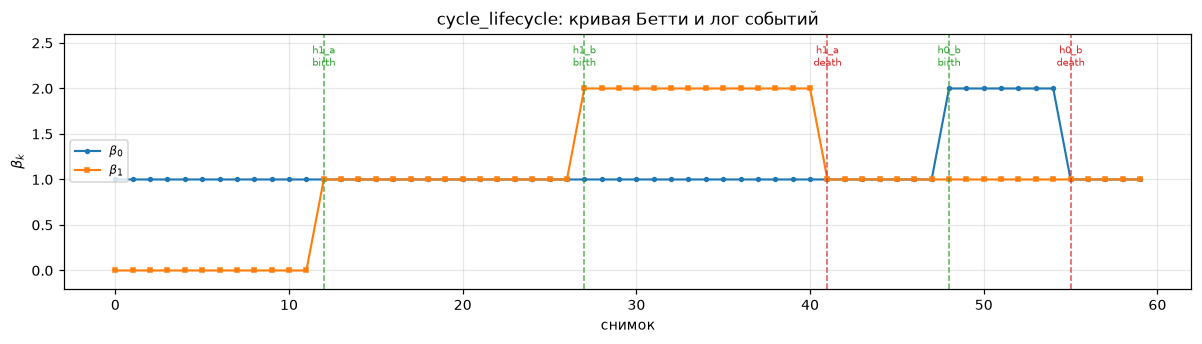

 снимок  dim     тип   признак   нарратив
------------------------------------------------------------------------------
     12    1   birth      h1_a   путь замыкается в цикл
     27    1   birth      h1_b   хорда делит цикл на два
     41    1   death      h1_a   удалено ребро дуги, отрезанной хордой
     48    0   birth      h0_b   от висячего пути отделяется компонента
     55    0   death      h0_b   компоненты сливаются обратно


In [9]:
lifecycle = build_dynamic_graph("cycle_lifecycle", CONFIG)
gt = lifecycle.ground_truth
curve, events = gt.betti_curve, gt.events

fig, ax = plt.subplots(figsize=(11, 3.2))
for dim, style in ((0, "-o"), (1, "-s")):
    ax.plot(curve[dim], style, ms=2.5, lw=1.4, label=f"$\\beta_{dim}$")
for e in events:
    ax.axvline(e.snapshot, color="tab:red" if e.type == "death" else "tab:green",
               ls="--", lw=1, alpha=0.8)
    ax.text(e.snapshot, 2.25, f"{e.feature_id}\n{e.type}", fontsize=6.5, ha="center",
            color="tab:red" if e.type == "death" else "tab:green")
ax.set_xlabel("снимок"); ax.set_ylabel(r"$\beta_k$"); ax.set_ylim(-0.2, 2.6)
ax.set_title("cycle_lifecycle: кривая Бетти и лог событий")
ax.legend(fontsize=8, loc="center left"); fig.tight_layout(); plt.show()

print(f"{'снимок':>7}{'dim':>5}{'тип':>8}{'признак':>10}   нарратив")
print("-" * 78)
for e in events:
    print(f"{e.snapshot:>7}{e.dim:>5}{e.type:>8}{e.feature_id:>10}   {e.narrative}")

### Два решения, которые выглядят произволом и им не являются

**Гибель на снимке 41 спарена с рождением на 12 (`h1_a`), а не на 27.** Разложение
зигзаг-модуля на интервальные модули однозначно (Крулль–Шмидт для колчана типа $A_n$),
поэтому парность определена и её нельзя назначить. Над $\mathbb{Z}/2$: $c_1$ — цикл
через хорду по дуге $0..12$, $c_2$ — по дуге $12..23..0$, $c = c_1 + c_2$ — исходный
24-цикл. Образы включений — различные прямые, интервалы получаются $[12, 40]$ и
$[27, \infty)$.

Интуиция «хорда разделила цикл на два, ломаем один — умирает молодой» здесь **неверна**.

**Цена ошибки:** лог с инвертированной парностью не ломает ни один тест внутри
семейства 2 — кривая Бетти парность не видит. Всплыло бы в Задаче 2 как систематически
«неверная» пара, и отладка пошла бы в алгоритм, а не в лог.

In [10]:
theta = lifecycle.snapshots[40]
broken = lifecycle.snapshots[41]
cx = reference.flag_complex(theta, threshold=gt.edge_threshold, max_homology_dim=2, max_nodes=30)
edges = cx.simplices(1)
position = {e: i for i, e in enumerate(edges)}
boundary = reference.boundary_matrix(cx, 1).astype(np.int64)

def chain(pairs):
    v = np.zeros(len(edges), dtype=np.int64)
    for p in pairs:
        v[position[tuple(sorted(p))]] = 1
    return v

cycle24 = chain([(i, i + 1) for i in range(23)] + [(23, 0)])
c2 = chain([(i, i + 1) for i in range(12, 23)] + [(23, 0), (0, 12)])
removed = position[(6, 7)]
betti41 = reference.betti_numbers_of_graph(broken, threshold=gt.edge_threshold,
                                           max_homology_dim=2, max_nodes=30)

print("Проверяется каноническая часть утверждения (тождество класса непроверяемо:")
print("базис H_1 тета-графа не канонический).\n")
print(f"  c  и c2 — циклы тета-графа:            {not (boundary @ cycle24 % 2).any()}, "
      f"{not (boundary @ c2 % 2).any()}")
print(f"  c  использует удалённое ребро (6,7):   {bool(cycle24[removed])}  -> c не в Z_1(G_41)")
print(f"  c2 не использует его:                  {not bool(c2[removed])}  -> c2 в Z_1(G_41)")
print(f"  dim Z_1(G_41) = beta_1(G_41) = {betti41[1]}          -> <c2> исчерпывает пережившее")
print("\n=> гибель в 41 спарена с рождением в 12.")

Проверяется каноническая часть утверждения (тождество класса непроверяемо:
базис H_1 тета-графа не канонический).

  c  и c2 — циклы тета-графа:            True, True
  c  использует удалённое ребро (6,7):   True  -> c не в Z_1(G_41)
  c2 не использует его:                  True  -> c2 в Z_1(G_41)
  dim Z_1(G_41) = beta_1(G_41) = 1          -> <c2> исчерпывает пережившее

=> гибель в 41 спарена с рождением в 12.


---
# S7. Метрический сценарий, осцилляторы, SBM

## geometric_loop — единственный набор с метрической фильтрацией

Точки на окружности с дышащим радиусом и управляемым разрывом дуги; на каждом кадре —
комплекс Рипса. Здесь цепочка совпадает с реальным динамическим коннектомом.

**$\varepsilon$ — не забытая ручка, а параметр качественного режима.** Снизу граф
рассыпается на $n$ компонент, сверху $\mathrm{VR}(S^1)$ уходит из режима $S^1$ в $S^3$
(Адамашек–Адамс), и гибель $\beta_1$ выглядит как «петля исчезла без причины».

In [11]:
loop_cfg = CONFIG.dynamic_events.scenarios.geometric_loop
n, radii = loop_cfg.n_points, loop_cfg.radius_schedule

def loop_betti(radius, eps, gap):
    ang = np.arange(n) * (2 * np.pi - gap) / (n - 1)
    p = np.c_[radius * np.cos(ang), radius * np.sin(ang)]
    d = np.linalg.norm(p[:, None] - p[None, :], axis=-1)
    w = (d <= eps).astype(float); np.fill_diagonal(w, 0.0)
    b = reference.betti_numbers_of_graph(w, threshold=0.5, max_homology_dim=2, max_nodes=30)
    return (b[0], b[1], b[2])

closed = 2 * np.pi / n
grid = [0.20, 0.30, 0.40, 0.80, 1.70, 1.90]
print("Окно по eps: beta при закрытой дуге\n")
print(f"{'eps':>6}" + "".join(f"{'R=' + str(R):>14}" for R in (1.0, 1.4)))
print("-" * 36)
for eps in grid:
    cells_ = "".join(f"{str(loop_betti(R, eps, closed)):>14}" for R in (1.0, 1.4))
    mark = ""
    if eps <= 0.30: mark = "  <- рассыпается"
    if eps >= 1.90: mark = "  <- режим S^3"
    print(f"{eps:>6}{cells_}{mark}")
print(f"\nпринято eps = {loop_cfg.rips_epsilon} — середина окна (0.367, 1.732) "
      f"в логарифмическом масштабе")

Окно по eps: beta при закрытой дуге

   eps         R=1.0         R=1.4
------------------------------------
   0.2    (24, 0, 0)    (24, 0, 0)  <- рассыпается
   0.3     (1, 1, 0)    (24, 0, 0)  <- рассыпается
   0.4     (1, 1, 0)     (1, 1, 0)
   0.8     (1, 1, 0)     (1, 1, 0)
   1.7     (1, 1, 0)     (1, 1, 0)
   1.9     (1, 0, 0)     (1, 1, 0)  <- режим S^3

принято eps = 0.8 — середина окна (0.367, 1.732) в логарифмическом масштабе


**Закрытое состояние дуги — $\delta = 2\pi/n$, а не ноль.** При нуле формула
$\theta_j = j(2\pi-\delta)/(n-1)$ ставит точки 0 и $n-1$ друг на друга: расстояние
$2.4\cdot10^{-16}$. Числа Бетти при этом **совпадают** — (1,1,0) в обоих случаях, —
поэтому тест согласованности прошёл бы, и вырождение осталось бы в наборе молча.
Ловится не по $\beta$, а по минимальному попарному расстоянию.

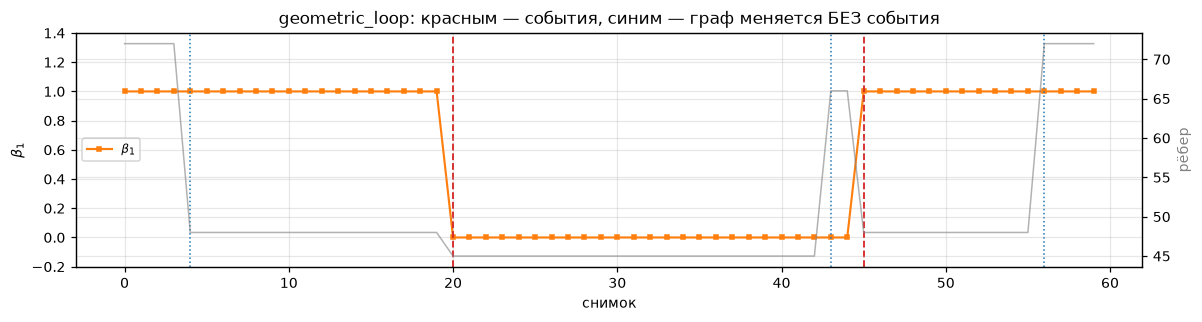

граф меняется на снимках: [4, 20, 43, 45, 56]
события запланированы на:  [20, 45]
дыхание радиуса без события: [4, 43, 56]
различных графов: 4 на 60 снимков


In [12]:
loop = build_dynamic_graph("geometric_loop", CONFIG)
lgt = loop.ground_truth
graphs = [adjacency_from_snapshot(s, edge_rule=lgt.edge_rule, edge_threshold=lgt.edge_threshold)
          for s in loop.snapshots]
changes = [t for t in range(1, len(graphs)) if not np.array_equal(graphs[t], graphs[t - 1])]
scheduled = {e.snapshot for e in lgt.events}

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(lgt.betti_curve[1], "-s", ms=2.5, lw=1.4, label=r"$\beta_1$", color="tab:orange")
ax2 = ax.twinx()
ax2.plot([int(g.sum() // 2) for g in graphs], lw=1, color="gray", alpha=0.6, label="рёбер")
ax2.set_ylabel("рёбер", color="gray")
for t in changes:
    is_event = t in scheduled
    ax.axvline(t, color="tab:red" if is_event else "tab:blue", ls="--" if is_event else ":",
               lw=1.2 if is_event else 1)
ax.set_xlabel("снимок"); ax.set_ylabel(r"$\beta_1$"); ax.set_ylim(-0.2, 1.4)
ax.set_title("geometric_loop: красным — события, синим — граф меняется БЕЗ события")
ax.legend(fontsize=8, loc="center left"); fig.tight_layout(); plt.show()

print(f"граф меняется на снимках: {changes}")
print(f"события запланированы на:  {sorted(scheduled)}")
print(f"дыхание радиуса без события: {[t for t in changes if t not in scheduled]}")
print(f"различных графов: {len({g.tobytes() for g in graphs})} на {len(graphs)} снимков")

Три снимка, где граф меняется без события, — **сильнейший отрицательный контроль
набора**: детектор, срабатывающий на смену комплекса, поймается здесь. Тест называет их
поимённо, потому что проверка «по всему диапазону» прошла бы и на наборе, где комплекс
вообще не менялся.

## Осцилляторы: ряд → скользящее окно → динамический граф

Аналог фМРТ: ряды с **известным** расписанием связи. Режим — это разбиение каналов
на блоки, и соседние разбиения обязаны быть связаны **измельчением**: переход
$[15,15] \to [10,10,10]$ не слияние и не деление, а перенарезка.

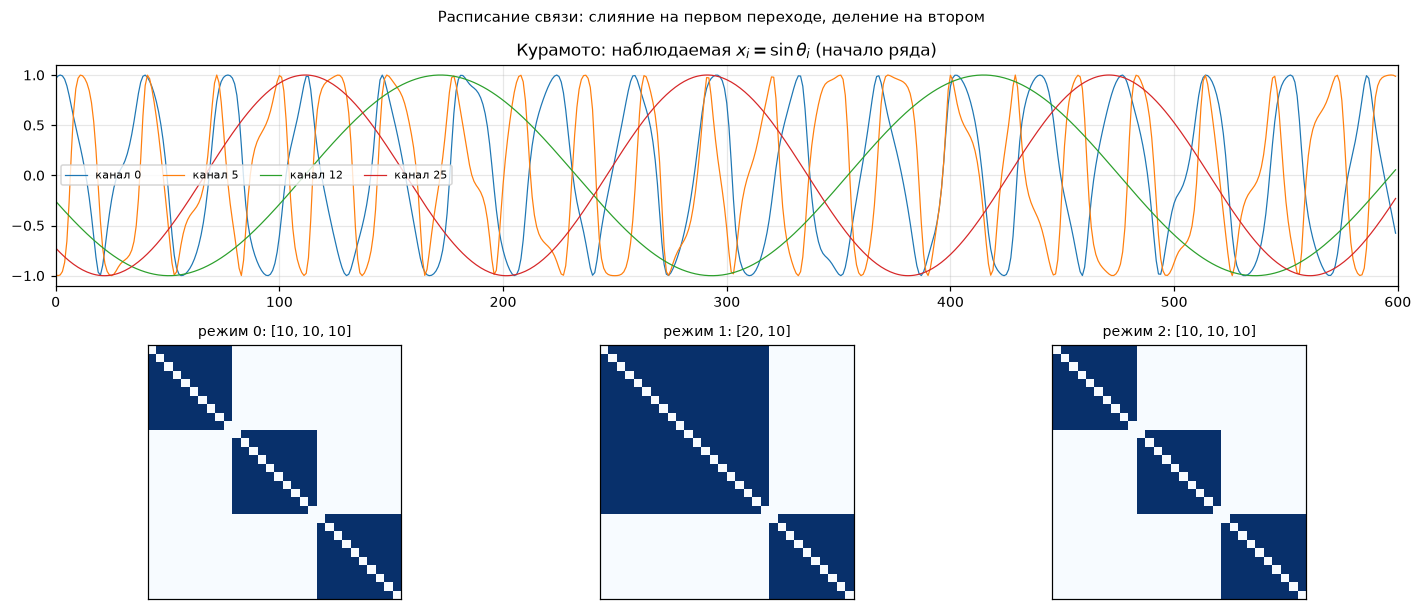

In [13]:
kuramoto = build_series("kuramoto", CONFIG)
osc, win = CONFIG.oscillators, CONFIG.sliding_window
schedule = osc.coupling_schedule

fig = plt.figure(figsize=(13, 5.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])

ax = fig.add_subplot(gs[0, :])
for ch in (0, 5, 12, 25):
    ax.plot(kuramoto.series[ch, :600], lw=0.8, label=f"канал {ch}")
for k in range(1, len(schedule.regimes)):
    ax.axvline(k * schedule.regime_length, color="k", ls="--", lw=1)
ax.set_xlim(0, 600); ax.set_title("Курамото: наблюдаемая $x_i = \\sin\\theta_i$ (начало ряда)")
ax.legend(fontsize=7, ncol=4)

for i, (matrix, partition) in enumerate(zip(kuramoto.coupling, schedule.regimes)):
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(matrix, cmap="Blues"); ax.set_title(f"режим {i}: {list(partition)}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Расписание связи: слияние на первом переходе, деление на втором", fontsize=10)
fig.tight_layout(); plt.show()

In [14]:
corr = sw.correlation_windows(kuramoto.series, length=win.length, step=win.step)
sim = sw.similarity_from_correlation(corr)
starts = sw.window_starts(osc.n_timepoints, length=win.length, step=win.step)
off = ~np.eye(osc.n_channels, dtype=bool)

grouped = {}
for i, s in enumerate(starts):
    r = sw.regime_of_window(int(s), length=win.length, regime_length=schedule.regime_length,
                            n_regimes=len(schedule.regimes))
    if r is not None:
        grouped.setdefault(r, []).append(sim[i])

print("Согласие восстановленной связности с истинным A(t)")
print(f"(усреднённая по окнам режима матрица |r| против A этого режима)\n")
print(f"{'режим':>7}{'разбиение':>16}{'согласие':>11}")
print("-" * 34)
for r, mats in sorted(grouped.items()):
    mean = np.mean(mats, axis=0)
    agreement = float(np.corrcoef(mean[off], kuramoto.coupling[r][off])[0, 1])
    print(f"{r:>7}{str(list(schedule.regimes[r])):>16}{agreement:>11.3f}")
print(f"\nпорог min_coupling_agreement = {win.min_coupling_agreement}")

Согласие восстановленной связности с истинным A(t)
(усреднённая по окнам режима матрица |r| против A этого режима)

  режим       разбиение   согласие
----------------------------------
      0    [10, 10, 10]      0.395
      1        [20, 10]      0.688
      2    [10, 10, 10]      0.383

порог min_coupling_agreement = 0.25


**Чего эта статистика не делает: она не различает режимы.** Согласие с *чужим*
режимом доходит до 0.440 при истинном минимуме 0.383 — классы перекрываются, и никакой
порог их не разделит. Это следствие вложенности разбиений: $[20,10]$ — огрубление
$[10,10,10]$, соседние режимы совпадают большей частью структуры. Честный нулевой
контроль — перестановка меток каналов: $-0.039\ldots0.068$ против истинных
$0.383\ldots0.878$.

**Окно ограничено с двух сторон.** Сверху — длительностью режима, снизу — периодом
колебания: при 0.16 периода в окне корреляция внутри блока (0.946) и между блоками
(0.936) неразличимы, и связь не восстанавливается вовсе.

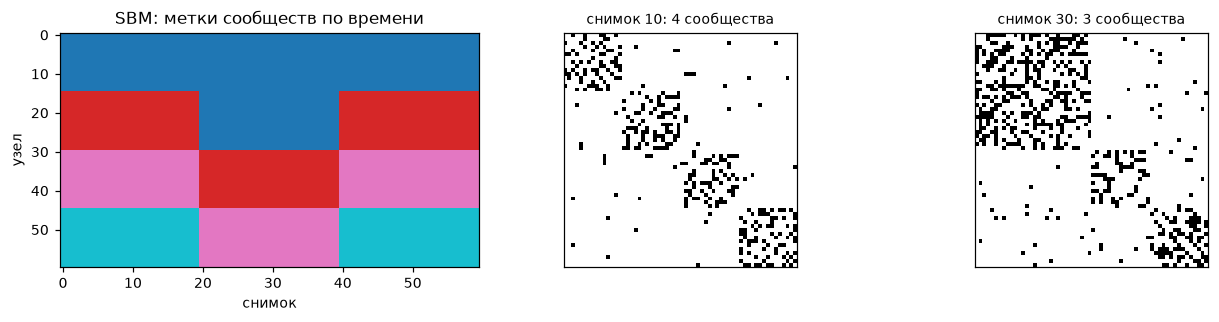

truth_kind = partition, betti_curve = None
компонент после удаления изолированных вершин, по всем снимкам: [1]


In [15]:
sbm = build_dynamic_sbm(CONFIG)
labels = sbm.ground_truth.community_labels

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].imshow(labels.T, aspect="auto", cmap="tab10", interpolation="nearest")
ax[0].set_xlabel("снимок"); ax[0].set_ylabel("узел"); ax[0].grid(False)
ax[0].set_title("SBM: метки сообществ по времени")
for i, t in enumerate((10, 30)):
    ax[i + 1].imshow(sbm.snapshots[t], cmap="Greys", interpolation="nearest")
    ax[i + 1].set_title(f"снимок {t}: {len(set(labels[t]))} сообщества", fontsize=9)
    ax[i + 1].set_xticks([]); ax[i + 1].set_yticks([]); ax[i + 1].grid(False)
fig.tight_layout(); plt.show()

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
comps = set()
for s in sbm.snapshots:
    a = s > 0.5; keep = a.sum(1) > 0
    comps.add(connected_components(csr_matrix(a[np.ix_(keep, keep)]), directed=False)[0])
print(f"truth_kind = {sbm.ground_truth.truth_kind}, betti_curve = {sbm.ground_truth.betti_curve}")
print(f"компонент после удаления изолированных вершин, по всем снимкам: {sorted(comps)}")

**Слияние сообществ не является гомологическим событием.** Блоки прошиты между
собой десятками рёбер (7–41 межблочных на снимке), граф связен, и слияние не меняет
ничего в гомологиях. $\beta_0$ всё же гуляет между 1 и 2 — но из-за случайных
изолированных вершин, а не из-за сообществ.

Поэтому у SBM `truth_kind: partition`, а `betti_curve` и `events` **не пишутся**:
измеренная кривая под именем истины была бы истиной как выходом пайплайна.

---
# S8. Шум и нулевые модели

## Устойчивость: граница $d_B \le 2\,d_H$, а не $d_H$

Двойка следует из параметризации: значение фильтрации симплекса в комплексе Рипса —
его **диаметр**, поэтому сдвиг каждой точки на $\delta$ меняет диаметр на $2\delta$.

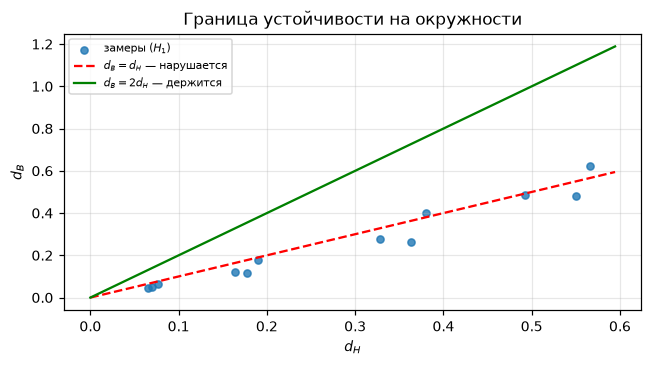

нарушений d_B <= d_H:    2 из 12, отношение до 1.10
нарушений d_B <= 2*d_H:  0 из 12


In [16]:
from persim import bottleneck

def dgm1(points):
    d = pairwise_distances(points)
    dg = persistence_diagrams(d, max_homology_dim=1, coeff_field=TOPOLOGY.coeff_field)[1]
    return dg[np.isfinite(dg[:, 1])]

def hausdorff(a, b):
    d = np.linalg.norm(a[:, None] - b[None, :], axis=-1)
    return max(d.min(1).max(), d.min(0).max())

base = build_static_cloud("circle", CONFIG, n_points=250, noise_sigma=0.0)
clean = dgm1(base.points)
levels = [0.02, 0.05, 0.10, 0.15]
rows = []
for lvl in levels:
    for seed in TOPOLOGY.calibration_seeds:
        pts = make_jittered_cloud(base.points, "b", lvl, 0, rng_for(seed, "nb_stab")).points
        rows.append((lvl, bottleneck(clean, dgm1(pts)), hausdorff(base.points, pts)))

fig, ax = plt.subplots(figsize=(6, 3.4))
db = np.array([r[1] for r in rows]); dh = np.array([r[2] for r in rows])
ax.scatter(dh, db, s=22, alpha=0.8, label=r"замеры ($H_1$)")
line = np.linspace(0, dh.max() * 1.05, 10)
ax.plot(line, line, "r--", label=r"$d_B = d_H$ — нарушается")
ax.plot(line, 2 * line, "g-", label=r"$d_B = 2 d_H$ — держится")
ax.set_xlabel(r"$d_H$"); ax.set_ylabel(r"$d_B$"); ax.legend(fontsize=7)
ax.set_title("Граница устойчивости на окружности")
fig.tight_layout(); plt.show()

print(f"нарушений d_B <= d_H:    {(db > dh).sum()} из {len(rows)}, отношение до {(db/dh).max():.2f}")
print(f"нарушений d_B <= 2*d_H:  {(db > 2*dh).sum()} из {len(rows)}")

**Ловушка:** в $H_0$ граница $d_B \le d_H$ не нарушается нигде — тест, написанный
только по нульмерным барам, прошёл бы и оставил неверную теорему в документе.

Замер выше сделан на 250 точках ради скорости ноутбука; в `method.md` §4.1 записан прогон
на 400 точках, где форму без двойки нарушают 5 комбинаций из 12 при отношении до 1.31.
Число нарушений зависит от выборки, направление — нет: границу $2d_H$ не нарушает ни одна
комбинация ни в одном прогоне.

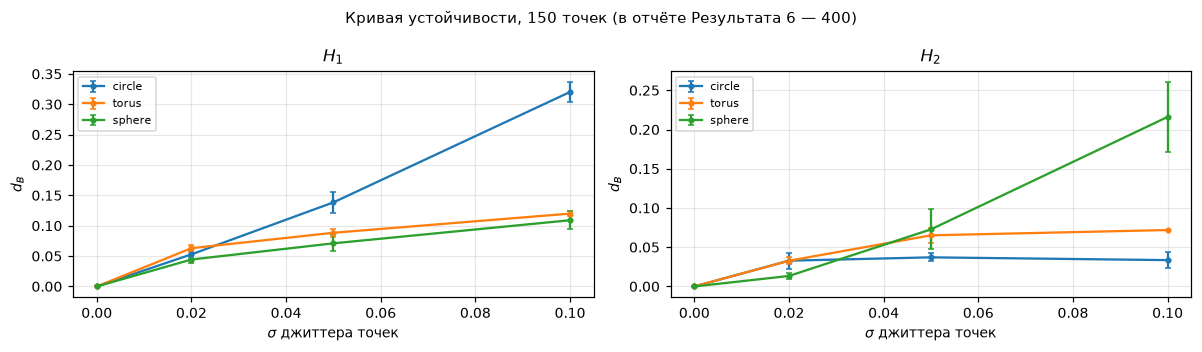

In [17]:
from tdadyn.synthetic.build import STABILITY_OBJECTS, stability_curve
import dataclasses

reduced = dataclasses.replace(
    CONFIG,
    static_clouds=dataclasses.replace(CONFIG.static_clouds, n_points=150),
    noise=dataclasses.replace(CONFIG.noise, n_repeats=3))
curve = stability_curve(reduced)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for dim, ax in zip(("H1", "H2"), axes):
    for name in STABILITY_OBJECTS:
        e = curve["objects"][name]
        ax.errorbar(e["levels"], e[dim]["mean"], yerr=e[dim]["spread"], marker="o", ms=3,
                    capsize=2, label=name)
    ax.set_xlabel(r"$\sigma$ джиттера точек"); ax.set_ylabel(r"$d_B$")
    ax.set_title(f"${dim[0]}_{dim[1]}$"); ax.legend(fontsize=7)
fig.suptitle(f"Кривая устойчивости, {curve['n_points']} точек "
             f"(в отчёте Результата 6 — {CONFIG.static_clouds.n_points})", fontsize=10)
fig.tight_layout(); plt.show()

**Одной окружности недостаточно.** Каждый объект информативен ровно в своей
размерности и плоск в другой: у окружности $H_2$ плоская, у сферы почти не двигается
$H_1$. Кривая по одному объекту информативна наполовину — а $H_2$ самое хрупкое место
пайплайна.

## Нулевые модели измеряют частоту ложных срабатываний, а не утверждают ноль

Формулировка «у нулевой модели нет значимых долгоживущих баров» **невыполнима**.
Случайный граф честно имеет циклы — это не артефакт, а нулевое распределение.

In [18]:
pairs = 24 * 23 // 2
print(f"ER на n=24, флаг-комплекс эталоном, 5 реализаций на плотность")
print(f"(плотность cycle_lifecycle: 24/{pairs} = {24/pairs:.3f})\n")
print(f"{'m':>5}{'p':>8}   типичное beta            чистых (1,0,0)")
print("-" * 62)
for m in (12, 24, 36, 60, 100, 180, 220):
    out, clean_n = [], 0
    for rep in range(5):
        r = rng_for(CONFIG.seed, "nb_er", rep)
        iu = np.triu_indices(24, 1)
        pick = r.choice(len(iu[0]), size=m, replace=False)
        a = np.zeros((24, 24)); a[iu[0][pick], iu[1][pick]] = 1.0; a = a + a.T
        b = reference.betti_numbers_of_graph(a, threshold=0.5, max_homology_dim=2, max_nodes=30)
        bb = (b[0], b[1], b[2]); out.append(bb); clean_n += bb == (1, 0, 0)
    print(f"{m:>5}{m/pairs:>8.3f}   {str(out[0]):<24}{clean_n}/5")

ER на n=24, флаг-комплекс эталоном, 5 реализаций на плотность
(плотность cycle_lifecycle: 24/276 = 0.087)

    m       p   типичное beta            чистых (1,0,0)
--------------------------------------------------------------
   12   0.043   (12, 0, 0)              0/5
   24   0.087   (4, 4, 0)               0/5
   36   0.130   (1, 10, 0)              0/5
   60   0.217   (1, 15, 0)              0/5
  100   0.362   (1, 3, 9)               0/5


  180   0.652   (1, 0, 0)               3/5
  220   0.797   (1, 0, 0)               5/5


Чисто становится только при $p \gtrsim 0.8$ — на почти полном графе, который
нулевой моделью ничего не контролирует. Поэтому истина нулевого набора: **расписания нет,
список событий пуст**. Это утверждение о конструкции, проверяемое на уровне генератора.

**У самого критерия есть ненулевая частота ложных срабатываний**, и она не сводится
к нулю размером выборки. Измерено на потоке генератора, 200 испытаний, $\mathbb{R}^3$:

| $n$ | Промахов | Частота | 95% сверху |
|---|---|---|---|
| 200 | 12/200 | 6.0% | 10.2% |
| 400 | 3/200 | **1.5%** | 4.3% |

Механизм: когда над шумовым полом уцелел ровно **один** бар, сравнивать его не с чем,
и одинокий выживший значим по построению. Порог в конфиге взят выше 95%-границы
истинной частоты, а не выше наблюдённого на калибровочных сидах нуля: шестьдесят
испытаний ноль не устанавливают.

---
# S9. Сборка и воспроизводимость

Одна команда собирает всё; манифест хранит sha256 массивов **и sha256 истины**.

In [19]:
e = next(x for x in ENTRIES if x.generator == "cycle_lifecycle")
print("Запись манифеста:\n")
for field in ("dataset_id", "family", "generator", "seed", "path"):
    print(f"  {field:<16}{getattr(e, field)}")
print(f"  {'arrays':<16}{ {k: v[:16] + '...' for k, v in e.arrays.items()} }")
print(f"  {'truth_sha256':<16}{e.truth_sha256[:16]}...")
print(f"\nОтбрасывается при сравнении пересборки: generated_at, package_version")
print("truth_sha256 НЕ отбрасывается: он воспроизводим, и потому входит в сравнение.")
print("\nБез него проверка «те же хеши» не покрывала бы ожидаемые числа Бетти,")
print("лог событий и notes: массивы при правке истины не меняются.")

Запись манифеста:

  dataset_id      cycle_lifecycle_N24_T60_w1_thr0.5_sched12-27-41-48-55_seed20260201
  family          dynamic_graph
  generator       cycle_lifecycle
  seed            20260201
  path            dynamic_graph/cycle_lifecycle_N24_T60_w1_thr0.5_sched12-27-41-48-55_seed20260201
  arrays          {'snapshots.npy': '0d25d71fa73eed39...'}
  truth_sha256    c1b5541bba25137b...

Отбрасывается при сравнении пересборки: generated_at, package_version
truth_sha256 НЕ отбрасывается: он воспроизводим, и потому входит в сравнение.

Без него проверка «те же хеши» не покрывала бы ожидаемые числа Бетти,
лог событий и notes: массивы при правке истины не меняются.


**Проверка нулевого уровня — бесплатная и ловит целый класс отказов.** sha256
возмущённого массива при уровне 0.0 равен sha256 базового; оба числа уже в манифесте.
Ловит неверно подключённую базу, сдвиг потока случайности между уровнями и безусловно
применённый `clip`.

**Оговорка о воспроизводимости.** Формулировка — «две сборки **в одной среде** дают
одинаковые записи». Больше обещать нельзя: Рёсслер при $c = 5.7$ хаотичен, и смена
версии scipy, метода или допусков уводит ряд целиком.

---
# Решения на развилках

Места, где спецификация допускала несколько прочтений, и то, чем выбор обоснован.

| Развилка | Решение | Почему |
|---|---|---|
| Критерий значимости | разрыв в спектре с шагом в пыль | старое правило: 9 промахов из 54, ошибается в обе стороны |
| Парность гибели $H_1$ | спарена с рождением при замыкании пути | разложение зигзаг-модуля однозначно; не конвенция |
| Закрытое состояние дуги | $\delta = 2\pi/n$, не ноль | при нуле две точки совпадают, а $\beta$ этого не видит |
| Род истины vs раскладка | отдельное поле `truth_kind` | SBM: на диске граф, истина — разбиение |
| Направление порога | поле `edge_rule` в истине | иначе метрический набор читается как дополнение |
| Истина SBM | разбиение; кривая не пишется | измеренная кривая = истина как выход пайплайна |
| Истина нулевых моделей | пустой лог событий | $(1,0,0)$ недостижимо ни при какой плотности |
| Раскладка семейства 4 | только возмущённый массив | пара «источник + производное» рассогласована в обе стороны |
| Порог согласия связности | калибровка на 3 сидах, нулевой контроль — перестановка меток | чужой режим не нулевой контроль: разбиения вложены |
| Граница устойчивости | $d_B \le 2 d_H$ | параметризация диаметром; при 400 точках 5 из 12 нарушают форму без двойки (`method.md` §4.1) |

---

# Ограничения

**Что эти данные не делают:**

- **Не заменяют реальные данные.** Динамика не претендует на реалистичность; ряды
  осцилляторов — аналог фМРТ по структуре связи, а не по спектру или уровню шума.
- **Не подтверждают научную осмысленность** набора для конкретной задачи. Тесты
  проверяют соответствие заявленной истине, и только.
- **Не дают универсальных порогов.** Параметры критерия откалиброваны на облаках
  семейства 1 в $\mathbb{R}^3$ и $\mathbb{R}^4$. На коннектомы Задачи 3 не переносятся:
  там иное распределение расстояний и, главное, нет известного $\beta_k$, относительно
  которого можно калиброваться.
- **Критерий не инвариантен к перепараметризации фильтрации.** Монотонное преобразование
  сходство → расстояние сохраняет структуру диаграммы, но искажает персистентности,
  а критерий сравнивает именно их.
- **Нулевые модели не утверждают отсутствие признаков** — они позволяют частоту ложных
  срабатываний измерить.
- **Воспроизводимость Рёсслера — в пределах одной среды.**
- **Wasserstein не считается**: мера расхождения диаграмм одна — bottleneck.

**Известные артефакты, которые не являются багами:** комплекс Рипса окружности при росте
масштаба последовательно эквивалентен $S^1, S^3, S^5,\dots$; числа Бетти по зашумлённой
выборке восстанавливаются только как персистентные; $H_0$ всегда содержит один
бесконечный бар.

---

# Что дальше

| | |
|---|---|
| **Задача 2** | зигзаг-алгоритмы и локализация событий — `docs/handoff.md` перечисляет ловушки |
| **Задача 3** | персистентные инварианты коннектомов; параметры критерия туда не наследуются |
| **Результат 6** | устойчивость и сложность; кривая производится сборкой по `--results` |